# Human Activity Recognition with a Hidden Markov Model (HMM)

This notebook collects motion data (accelerometer and gyroscope) with the Sensor Logger app, builds an HMM from scratch with NumPy (Baum-Welch training and Viterbi decoding), and tests it on unseen recordings.

**Pipeline:** load raw recordings, then clean and resample, then window, then extract features, then build and train the HMM, then evaluate on unseen data, then analysis.

---
## Step 1: Inspect one raw recording
Mounts Google Drive, lists the exported Sensor Logger `.zip` files, unzips the first one and shows the shape and first 3 rows of `Accelerometer.csv` and `Gyroscope.csv`. This confirms the column names (`time`, `seconds_elapsed`, `x`, `y`, `z`) before loading everything.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, os, pandas as pd

zip_dir = '/content/drive/MyDrive/hmm_project/raw_zip_files'
zips = sorted(os.listdir(zip_dir))
print(len(zips), 'files')
print(zips)

first_zip = os.path.join(zip_dir, zips[0])
with zipfile.ZipFile(first_zip) as z:
    z.extractall('/content/test_unzip')

for name in ['Accelerometer.csv', 'Gyroscope.csv']:
    df = pd.read_csv(os.path.join('/content/test_unzip', name))
    print('\n', name, df.shape)
    print(df.head(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
68 files
['Jumping_01-2026-10-23_10-13-29.zip', 'Jumping_02-2026-10-23_10-13-44.zip', 'Jumping_03-2026-10-23_10-13-55.zip', 'Jumping_04-2026-10-23_10-14-07.zip', 'Jumping_05-2026-10-23_10-14-55.zip', 'Jumping_06-2026-10-23_10-28-47.zip', 'Jumping_07-2026-10-23_10-28-58.zip', 'Jumping_08-2026-10-23_10-29-13.zip', 'Jumping_09-2026-10-23_10-29-25.zip', 'Jumping_10-2026-10-23_10-29-44.zip', 'Jumping_11-2026-10-23_10-30-00.zip', 'Jumping_12-2026-10-23_10-30-16.zip', 'Jumping_13-2026-10-23_10-30-37.zip', 'Jumping_14-2026-10-23_18-02-33.zip', 'Jumping_15-2026-10-23_18-02-48.zip', 'Jumping_16-2026-10-23_18-03-06.zip', 'Jumping_17-2026-10-23_18-03-26.zip', 'Standing_01-2026-10-23_10-08-36.zip', 'Standing_02-2026-10-23_10-08-44.zip', 'Standing_03-2026-10-23_10-09-05.zip', 'Standing_04-2026-10-23_10-09-12.zip', 'Standing_05-2026-10-23_10-11-16.zip', 'Standing_06-2026-10

## Step 2: Load all recordings and measure the real sampling rate
Reads `Accelerometer.csv` and `Gyroscope.csv` from every zip. The activity label is taken from the start of the file name (for example `Walking_07...` gives `walking`).

For each recording it computes the duration, the number of rows, the median sampling rate (from the time gaps) and the largest gap between samples. The summary table per activity checks that every activity has at least 90 s of data and flags clips shorter than 5 s.

**What to read in the output:** the phone delivered about 52.7 Hz even though 100 Hz was set in the app, and the worst gap of 0.02 s shows there were no dropouts.

In [ ]:
import zipfile, os, pandas as pd, numpy as np

zip_dir = '/content/drive/MyDrive/hmm_project/raw_zip_files'
zips = sorted(f for f in os.listdir(zip_dir) if f.endswith('.zip'))

raw = {}
rows = []
for f in zips:
    label = f.split('_')[0].lower()
    with zipfile.ZipFile(os.path.join(zip_dir, f)) as z:
        acc = pd.read_csv(z.open('Accelerometer.csv'))
        gyr = pd.read_csv(z.open('Gyroscope.csv'))
    raw[f] = (acc, gyr)
    t = acc['seconds_elapsed'].values
    rows.append({
        'file': f,
        'label': label,
        'acc_rows': len(acc),
        'gyro_rows': len(gyr),
        'duration_s': t[-1] - t[0],
        'rate_hz': 1 / np.median(np.diff(t)),
        'max_gap_s': np.max(np.diff(t)),
    })

summary = pd.DataFrame(rows)

print(summary.groupby('label').agg(
    files=('file', 'count'),
    total_duration_s=('duration_s', 'sum'),
    min_clip_s=('duration_s', 'min'),
    max_clip_s=('duration_s', 'max'),
    mean_rate_hz=('rate_hz', 'mean'),
    worst_gap_s=('max_gap_s', 'max'),
).round(2))

print('\nClips shorter than 5 s:')
print(summary[summary['duration_s'] < 5][['file', 'duration_s']].round(2))

          files  total_duration_s  min_clip_s  max_clip_s  mean_rate_hz  \
label                                                                     
jumping      17            110.82        4.89        9.94         52.71   
standing     17            112.45        5.21        9.70         52.72   
still        17            122.50        5.41        9.30         52.68   
walking      17            121.89        5.28       10.52         52.70   

          worst_gap_s  
label                  
jumping          0.02  
standing         0.02  
still            0.02  
walking          0.02  

Clips shorter than 5 s:
                                  file  duration_s
1   Jumping_02-2026-10-23_10-13-44.zip        4.93
8   Jumping_09-2026-10-23_10-29-25.zip        4.94
12  Jumping_13-2026-10-23_10-30-37.zip        4.89


## Step 3: Clean and harmonize the sampling rate
For each recording this cell:
1. trims 0.5 s from the start and end (the movement of pressing start and stop),
2. aligns the accelerometer and gyroscope on their shared time range,
3. resamples both to a uniform **50 Hz** grid with linear interpolation (this is the harmonized sampling rate),
4. saves the clean CSV files (with the label column) to the `clean` folder in Drive.

The summary shows total duration per activity after trimming (about 93 to 105 s each).

In [ ]:
import numpy as np, pandas as pd, os

FS = 50          # target sampling rate (Hz)
TRIM = 0.5       # seconds trimmed from each end
clean_dir = '/content/drive/MyDrive/hmm_project/clean'
os.makedirs(clean_dir, exist_ok=True)

clean = {}
for f, (acc, gyr) in raw.items():
    label = f.split('_')[0].lower()
    t0 = max(acc['seconds_elapsed'].min(), gyr['seconds_elapsed'].min()) + TRIM
    t1 = min(acc['seconds_elapsed'].max(), gyr['seconds_elapsed'].max()) - TRIM
    t = np.arange(t0, t1, 1 / FS)

    df = pd.DataFrame({'t': t - t[0]})
    for ax in ['x', 'y', 'z']:
        df['acc_' + ax] = np.interp(t, acc['seconds_elapsed'], acc[ax])
        df['gyro_' + ax] = np.interp(t, gyr['seconds_elapsed'], gyr[ax])
    df['label'] = label

    name = f.replace('.zip', '.csv')
    df.to_csv(os.path.join(clean_dir, name), index=False)
    clean[name] = df

summary2 = pd.DataFrame([
    {'file': k, 'label': v['label'].iloc[0], 'rows': len(v), 'duration_s': v['t'].iloc[-1]}
    for k, v in clean.items()
])
print(summary2.groupby('label').agg(
    files=('file', 'count'),
    total_duration_s=('duration_s', 'sum'),
    min_clip_s=('duration_s', 'min'),
    max_clip_s=('duration_s', 'max'),
).round(2))

          files  total_duration_s  min_clip_s  max_clip_s
label                                                    
jumping      17             93.18        3.88        8.86
standing     17             94.98        4.18        8.68
still        17            105.12        4.40        8.28
walking      17            104.36        4.28        9.50


## Step 4: Plot sample signals
Plots one clip per activity, with the accelerometer (x, y, z) on the left and the gyroscope (x, y, z) on the right, and saves the figure as `sample_signals.png`.

**What to look for:** jumping has large regular peaks, walking a medium oscillation, standing a small wobble, and still an almost flat signal. The still gyroscope is about 100 times smaller than the standing gyroscope.

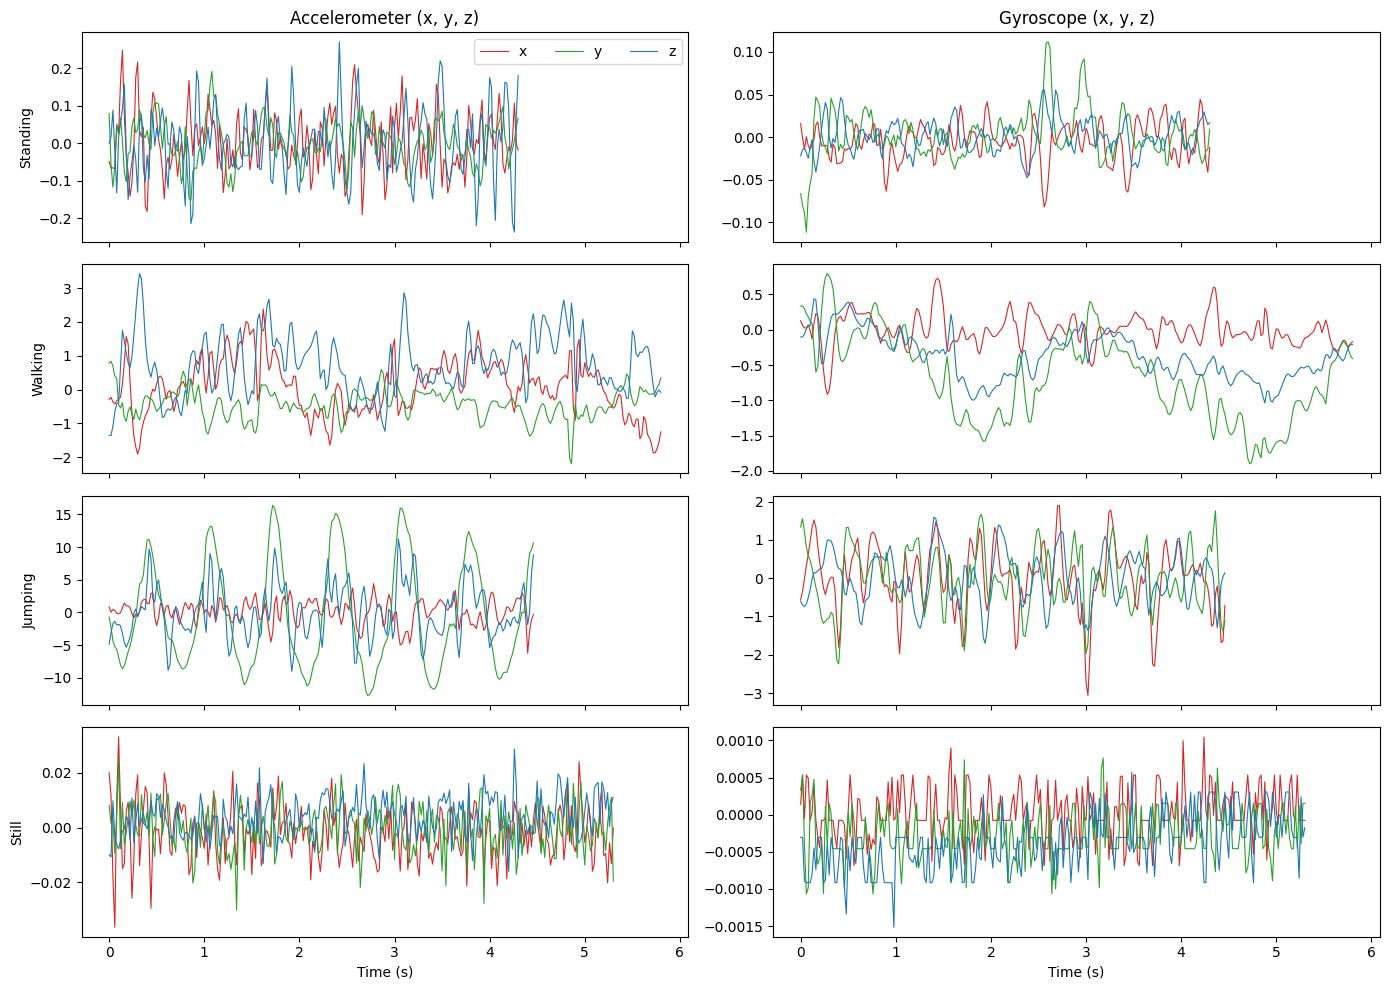

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd, numpy as np, os, glob

# Reload from Drive in case the Colab session restarted
clean_dir = '/content/drive/MyDrive/hmm_project/clean'
clean = {os.path.basename(p): pd.read_csv(p) for p in sorted(glob.glob(clean_dir + '/*.csv'))}

activities = ['standing', 'walking', 'jumping', 'still']
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)

for i, act in enumerate(activities):
    name = next(k for k, v in clean.items() if v['label'].iloc[0] == act)
    df = clean[name]
    for ax_name, c in zip(['x', 'y', 'z'], ['tab:red', 'tab:green', 'tab:blue']):
        axes[i, 0].plot(df['t'], df['acc_' + ax_name], color=c, label=ax_name, lw=0.8)
        axes[i, 1].plot(df['t'], df['gyro_' + ax_name], color=c, label=ax_name, lw=0.8)
    axes[i, 0].set_ylabel(act.capitalize())
    if i == 0:
        axes[i, 0].set_title('Accelerometer (x, y, z)')
        axes[i, 1].set_title('Gyroscope (x, y, z)')
        axes[i, 0].legend(loc='upper right', ncol=3)

axes[-1, 0].set_xlabel('Time (s)')
axes[-1, 1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/hmm_project/sample_signals.png', dpi=150)
plt.show()

## Step 5: Cut the signals into windows
Each clean recording is cut into windows of **2 s = 100 samples** (at 50 Hz) with **50% overlap**.

The window size was chosen so that a window holds about three jumping cycles (about 0.7 s each) and two to three walking steps, and the frequency resolution is 50 / 100 = 0.5 Hz, which is enough to tell walking (about 1.4 Hz) from jumping. The printed counts show how many windows each activity produced.

In [ ]:
import numpy as np, pandas as pd, glob, os

FS = 50
WIN = 2 * FS
STEP = WIN // 2

clean_dir = '/content/drive/MyDrive/hmm_project/clean'
clean = {os.path.basename(p): pd.read_csv(p) for p in sorted(glob.glob(clean_dir + '/*.csv'))}

cols = ['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z']

windows = []
for name, df in clean.items():
    label = df['label'].iloc[0]
    arr = df[cols].values
    for k, s in enumerate(range(0, len(arr) - WIN + 1, STEP)):
        windows.append({'file': name, 'label': label, 'idx': k, 'data': arr[s:s + WIN]})

info = pd.DataFrame([{'file': w['file'], 'label': w['label']} for w in windows])
print('Total windows:', len(windows))
print(info.groupby('label').size())
print('Window shape:', windows[0]['data'].shape)

Total windows: 296
label
jumping     66
standing    68
still       82
walking     80
dtype: int64
Window shape: (100, 6)


## Step 6: Feature extraction and normalization
Computes **8 features** per window.

| Domain | Feature | Meaning |
|---|---|---|
| Time | `acc_std` | Standard deviation of the accelerometer magnitude (movement intensity) |
| Time | `acc_sma` | Signal magnitude area of the accelerometer |
| Time | `gyro_std` | Standard deviation of the gyroscope magnitude (rotation intensity) |
| Time | `acc_corr` | Mean absolute correlation between the accelerometer axes |
| Frequency (FFT) | `acc_domfreq` | Dominant frequency of the accelerometer magnitude |
| Frequency (FFT) | `acc_energy` | Spectral energy |
| Frequency (FFT) | `acc_entropy` | Spectral entropy (low for periodic motion, high for noise) |
| Frequency (FFT) | `gyro_domfreq` | Dominant frequency of the gyroscope magnitude |

`fft_feats` applies a Hann window, removes the mean, and ignores the DC bin. The std, SMA and energy features go through `log10` because their values span several orders of magnitude. All features are then **Z-scored**, with the mean and standard deviation computed on the training windows only (saved in `features_train.npz` so the test files can reuse them).

The printed tables show the raw feature means per activity and check that the Z-scored features have mean 0 and std 1.

In [ ]:
import numpy as np, pandas as pd

FS = 50
EPS = 1e-8

def fft_feats(sig):
    """Dominant freq, spectral energy, spectral entropy of a 1-D signal."""
    sig = sig - sig.mean()
    N = len(sig)
    X = np.fft.rfft(sig * np.hanning(N))
    freqs = np.fft.rfftfreq(N, d=1 / FS)
    p = np.abs(X[1:]) ** 2          # drop DC bin
    f = freqs[1:]
    dom = f[np.argmax(p)]
    energy = p.sum() / N
    pn = p / (p.sum() + EPS)
    entropy = -(pn * np.log2(pn + EPS)).sum() / np.log2(len(pn))
    return dom, energy, entropy

def extract(w):
    acc, gyr = w[:, :3], w[:, 3:]
    acc_mag = np.linalg.norm(acc, axis=1)
    gyr_mag = np.linalg.norm(gyr, axis=1)

    acc_std = acc_mag.std()
    acc_sma = np.abs(acc).sum(axis=1).mean()
    gyro_std = gyr_mag.std()

    c = np.corrcoef(acc.T)
    acc_corr = np.nanmean(np.abs(c[np.triu_indices(3, 1)]))

    a_dom, a_en, a_ent = fft_feats(acc_mag)
    g_dom, _, _ = fft_feats(gyr_mag)

    return [np.log10(acc_std + EPS), np.log10(acc_sma + EPS), np.log10(gyro_std + EPS),
            acc_corr, a_dom, np.log10(a_en + EPS), a_ent, g_dom]

feat_names = ['acc_std', 'acc_sma', 'gyro_std', 'acc_corr',
              'acc_domfreq', 'acc_energy', 'acc_entropy', 'gyro_domfreq']

F = np.array([extract(w['data']) for w in windows])
labels = np.array([w['label'] for w in windows])
files = np.array([w['file'] for w in windows])
F = np.nan_to_num(F)

mu, sd = F.mean(axis=0), F.std(axis=0) + EPS
Z = (F - mu) / sd

np.savez('/content/drive/MyDrive/hmm_project/features_train.npz',
         Z=Z, F=F, labels=labels, files=files, mu=mu, sd=sd, names=feat_names)

print('Feature matrix:', Z.shape)
print('\nMean of RAW features per activity:')
print(pd.DataFrame(F, columns=feat_names).assign(label=labels).groupby('label').mean().round(2))
print('\nZ-score check (should be ~0 and ~1):')
print(pd.DataFrame({'mean': Z.mean(0), 'std': Z.std(0)}, index=feat_names).round(2))

Feature matrix: (296, 8)

Mean of RAW features per activity:
          acc_std  acc_sma  gyro_std  acc_corr  acc_domfreq  acc_energy  \
label                                                                     
jumping      0.64     1.09     -0.25      0.45         3.31        2.53   
standing    -1.17    -0.70     -1.63      0.20         2.52       -1.08   
still       -2.24    -1.72     -3.59      0.09         8.09       -3.24   
walking     -0.22     0.22     -0.65      0.19         1.41        0.82   

          acc_entropy  gyro_domfreq  
label                                
jumping          0.51          2.67  
standing         0.83          2.10  
still            0.89          7.77  
walking          0.64          1.08  

Z-score check (should be ~0 and ~1):
              mean  std
acc_std        0.0  1.0
acc_sma       -0.0  1.0
gyro_std       0.0  1.0
acc_corr      -0.0  1.0
acc_domfreq    0.0  1.0
acc_energy     0.0  1.0
acc_entropy   -0.0  1.0
gyro_domfreq  -0.0  1.0


## Step 7: Build the training sequences
Each recorded clip contains only one activity, so training on single clips would teach the HMM almost only self-transitions. This cell chains **one clip per activity, in random order** (fixed seed 42), into longer "sessions" that contain all four activities.

This gives 17 training sequences (one per clip index). **Limitation:** the switches between activities in these sequences come from the random ordering, not from real behavior, so the off-diagonal values of the learned transition matrix should not be read as habits.

In [ ]:
import numpy as np, pandas as pd
from scipy.special import logsumexp

STATES = ['standing', 'walking', 'jumping', 'still']
d = np.load('/content/drive/MyDrive/hmm_project/features_train.npz', allow_pickle=True)
Z, labels, files = d['Z'], d['labels'], d['files']

rng = np.random.default_rng(42)
clips = {a: [] for a in STATES}
for f in dict.fromkeys(files):
    m = files == f
    clips[labels[m][0]].append((Z[m], labels[m]))
n_sessions = min(len(v) for v in clips.values())
seqs, ys = [], []
for a in STATES:
    rng.shuffle(clips[a])
for s in range(n_sessions):
    order = rng.permutation(4)
    X = np.vstack([clips[STATES[o]][s][0] for o in order])
    y = np.concatenate([[STATES.index(l) for l in clips[STATES[o]][s][1]] for o in order])
    seqs.append(X); ys.append(y)
print(f'{len(seqs)} training sequences, {sum(len(x) for x in seqs)} windows')

17 training sequences, 296 windows


## Step 8: The Gaussian HMM class (from scratch, NumPy only)
Defines `GaussianHMM`. There is no output; run the cell once.

| Method | What it does |
|---|---|
| `init_supervised` | Starting values from the labelled windows: mean and variance per state, and A and pi from counts with add-one smoothing |
| `log_emission` | Log-probability of each window under each state's Gaussian (diagonal covariance) |
| `forward` / `backward` | Forward and backward passes in log space (with `logsumexp`) for numerical stability |
| `viterbi` | Most likely state sequence for a sequence of windows |
| `fit` | **Baum-Welch (EM)**: E-step with forward-backward, M-step updating pi, A, means and variances. Stops when the change in total log-likelihood is below `tol` (the convergence check), with `max_iter` as a safety limit |

`var_floor` stops a variance from collapsing to zero.

In [ ]:
class GaussianHMM:
    def __init__(self, n_states, var_floor=1e-2):
        self.N, self.floor = n_states, var_floor

    def init_supervised(self, seqs, ys):
        X, y = np.vstack(seqs), np.concatenate(ys)
        self.mu = np.array([X[y == i].mean(0) for i in range(self.N)])
        self.var = np.array([np.maximum(X[y == i].var(0), self.floor) for i in range(self.N)])
        A = np.ones((self.N, self.N))
        pi = np.ones(self.N)
        for yy in ys:
            pi[yy[0]] += 1
            for a, b in zip(yy[:-1], yy[1:]):
                A[a, b] += 1
        self.A = A / A.sum(1, keepdims=True)
        self.pi = pi / pi.sum()

    def log_emission(self, X):
        out = np.zeros((len(X), self.N))
        for i in range(self.N):
            out[:, i] = -0.5 * (np.log(2 * np.pi * self.var[i]) +
                                (X - self.mu[i]) ** 2 / self.var[i]).sum(1)
        return out

    def forward(self, logB):
        T = len(logB); logA = np.log(self.A + 1e-300)
        alpha = np.zeros((T, self.N))
        alpha[0] = np.log(self.pi + 1e-300) + logB[0]
        for t in range(1, T):
            alpha[t] = logB[t] + logsumexp(alpha[t - 1][:, None] + logA, axis=0)
        return alpha, logsumexp(alpha[-1])

    def backward(self, logB):
        T = len(logB); logA = np.log(self.A + 1e-300)
        beta = np.zeros((T, self.N))
        for t in range(T - 2, -1, -1):
            beta[t] = logsumexp(logA + logB[t + 1] + beta[t + 1], axis=1)
        return beta

    def viterbi(self, X):
        logB = self.log_emission(X); logA = np.log(self.A + 1e-300)
        T = len(X)
        delta = np.zeros((T, self.N)); psi = np.zeros((T, self.N), dtype=int)
        delta[0] = np.log(self.pi + 1e-300) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA
            psi[t] = scores.argmax(0)
            delta[t] = scores.max(0) + logB[t]
        path = np.zeros(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path

    def fit(self, seqs, tol=1e-3, max_iter=200):
        history = []
        for it in range(max_iter):
            pi_acc = np.zeros(self.N)
            xi_acc = np.zeros((self.N, self.N))
            g_sum = np.zeros(self.N)
            gx = np.zeros_like(self.mu); gxx = np.zeros_like(self.mu)
            total_ll = 0.0
            logA = np.log(self.A + 1e-300)
            for X in seqs:                               # E-step
                logB = self.log_emission(X)
                alpha, ll = self.forward(logB)
                beta = self.backward(logB)
                total_ll += ll
                gamma = np.exp(alpha + beta - ll)
                pi_acc += gamma[0]
                for t in range(len(X) - 1):
                    xi_acc += np.exp(alpha[t][:, None] + logA +
                                     logB[t + 1] + beta[t + 1] - ll)
                g_sum += gamma.sum(0)
                gx += gamma.T @ X
                gxx += gamma.T @ (X ** 2)

            self.pi = (pi_acc + 1e-6) / (pi_acc + 1e-6).sum()
            self.A = (xi_acc + 1e-6) / (xi_acc + 1e-6).sum(1, keepdims=True)
            self.mu = gx / g_sum[:, None]
            self.var = np.maximum(gxx / g_sum[:, None] - self.mu ** 2, self.floor)
            history.append(total_ll)
            if it > 0 and abs(history[-1] - history[-2]) < tol:   # convergence check
                print(f'Converged at iteration {it + 1} (|dLL| < {tol})')
                break
        else:
            print('Reached max_iter without converging')
        return history

## Step 9: Initialize the model and check accuracy before training
Creates the HMM with 4 states (standing, walking, jumping, still), initializes it from the labels, and measures how well Viterbi decodes the training sequences before any Baum-Welch update.

A value of 1.000 here is expected, because the model starts from the labels. It is not a test result; the unseen data later is.

In [ ]:
hmm = GaussianHMM(4)
hmm.init_supervised(seqs, ys)

def accuracy(model):
    pred = np.concatenate([model.viterbi(X) for X in seqs])
    true = np.concatenate(ys)
    return (pred == true).mean(), pred, true

acc0, _, _ = accuracy(hmm)
print(f'Training accuracy BEFORE Baum-Welch: {acc0:.3f}')

Training accuracy BEFORE Baum-Welch: 1.000


## Step 10: Train with Baum-Welch
Runs Baum-Welch until the log-likelihood changes by less than 1e-3 (convergence check) and prints:
- the log-likelihood from the first to the last iteration and the number of iterations,
- the training accuracy after training,
- the learned **transition matrix A** and **initial probabilities**,
- the training confusion matrix.

The model converged in 3 iterations, because the supervised initialization was already close to the optimum. The learned parameters are saved to `hmm_params.npz`.

In [ ]:
hist = hmm.fit(seqs, tol=1e-3)
print('Log-likelihood: first', round(hist[0], 2), '-> last', round(hist[-1], 2),
      f'({len(hist)} iterations)')

acc1, pred, true = accuracy(hmm)
print(f'Training accuracy AFTER Baum-Welch: {acc1:.3f}')

print('\nLearned transition matrix A (rows = from, cols = to):')
print(pd.DataFrame(hmm.A, index=STATES, columns=STATES).round(3))
print('\nInitial probabilities:', dict(zip(STATES, hmm.pi.round(3))))
print('\nConfusion (rows = true, cols = predicted):')
print(pd.crosstab(pd.Series(true).map(dict(enumerate(STATES))),
                  pd.Series(pred).map(dict(enumerate(STATES)))))

np.savez('/content/drive/MyDrive/hmm_project/hmm_params.npz',
         A=hmm.A, pi=hmm.pi, mu=hmm.mu, var=hmm.var, ll_history=np.array(hist))

Converged at iteration 3 (|dLL| < 0.001)
Log-likelihood: first 533.07 -> last 534.23 (3 iterations)
Training accuracy AFTER Baum-Welch: 1.000

Learned transition matrix A (rows = from, cols = to):
          standing  walking  jumping  still
standing     0.773    0.030    0.121  0.076
walking      0.065    0.818    0.052  0.065
jumping      0.033    0.083    0.817  0.067
still        0.026    0.066    0.053  0.855

Initial probabilities: {'standing': np.float64(0.471), 'walking': np.float64(0.294), 'jumping': np.float64(0.059), 'still': np.float64(0.176)}

Confusion (rows = true, cols = predicted):
col_0     jumping  standing  still  walking
row_0                                      
jumping        66         0      0        0
standing        0        68      0        0
still           0         0     82        0
walking         0         0      0       80


## Step 11: Visualize the transition matrix and the training curve
Left: **heatmap of the transition matrix A** (rows are the "from" state, columns the "to" state). Right: the **Baum-Welch log-likelihood** per iteration. The figure is saved as `transition_and_ll.png`.

The diagonal is strong (0.77 to 0.86), so each activity tends to continue from one window to the next. The y-axis of the curve spans only about 1 unit, so the visible rise is small.

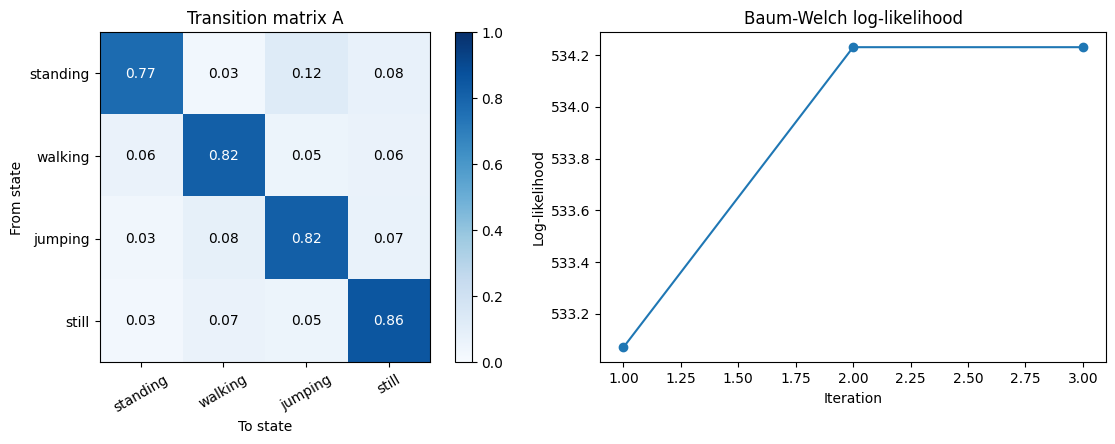

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

im = ax[0].imshow(hmm.A, cmap='Blues', vmin=0, vmax=1)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(STATES, rotation=30)
ax[0].set_yticks(range(4)); ax[0].set_yticklabels(STATES)
for i in range(4):
    for j in range(4):
        ax[0].text(j, i, f'{hmm.A[i, j]:.2f}', ha='center', va='center',
                   color='white' if hmm.A[i, j] > 0.5 else 'black')
ax[0].set_title('Transition matrix A')
ax[0].set_xlabel('To state'); ax[0].set_ylabel('From state')
plt.colorbar(im, ax=ax[0])

ax[1].plot(range(1, len(hist) + 1), hist, marker='o')
ax[1].set_title('Baum-Welch log-likelihood')
ax[1].set_xlabel('Iteration'); ax[1].set_ylabel('Log-likelihood')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/hmm_project/transition_and_ll.png', dpi=150)
plt.show()

## Step 12: Visualize the emission parameters
Heatmap of the **mean of each Z-scored feature for each state**, which are the means of the Gaussian emission distributions B. Saved as `emissions.png`.

For example, still is lowest on the intensity features and highest on the dominant-frequency features, and jumping has the highest intensity and the lowest spectral entropy. This figure shows the means only; the variances are also part of B.

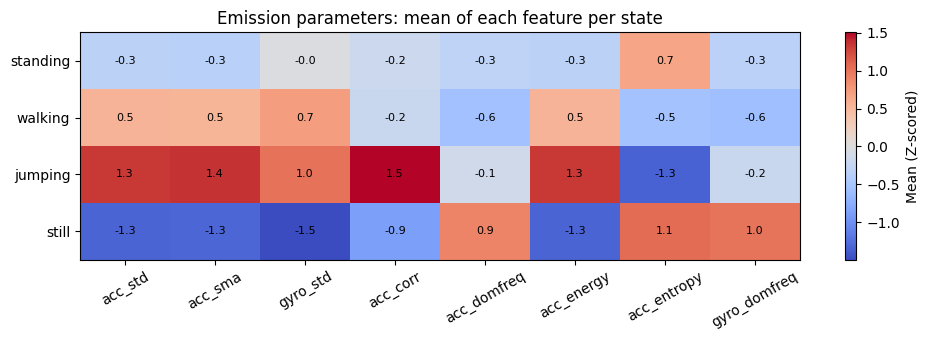

In [ ]:
feat_names = ['acc_std', 'acc_sma', 'gyro_std', 'acc_corr',
              'acc_domfreq', 'acc_energy', 'acc_entropy', 'gyro_domfreq']

plt.figure(figsize=(10, 3.5))
plt.imshow(hmm.mu, cmap='coolwarm', aspect='auto')
plt.xticks(range(8), feat_names, rotation=30)
plt.yticks(range(4), STATES)
for i in range(4):
    for j in range(8):
        plt.text(j, i, f'{hmm.mu[i, j]:.1f}', ha='center', va='center', fontsize=8)
plt.colorbar(label='Mean (Z-scored)')
plt.title('Emission parameters: mean of each feature per state')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/hmm_project/emissions.png', dpi=150)
plt.show()

---
## Step 13: Unseen test data, settings and ground truth
Sets the constants (same as training) and the **ground truth** for the two unseen recordings, as `(activity, start_s, end_s)` segments from my timing notes.

For `Test_file_02`, the switch times were refined from 10 s to 9.3 s and from 30 s to 29.1 s by looking at the accelerometer signal (not at the model's predictions).

In [ ]:
import zipfile, os, numpy as np, pandas as pd, matplotlib.pyplot as plt

FS, WIN, STEP, TRIM, EPS = 50, 100, 50, 0.5, 1e-8
STATES = ['standing', 'walking', 'jumping', 'still']
test_dir = '/content/drive/MyDrive/hmm_project/test_files'


truth = {
    'Test_file_01': [('walking', 0, 10), ('jumping', 10, 20), ('still', 20, 30), ('standing', 30, 1e9)],
    'Test_file_02': [('still', 0, 9.3), ('walking', 9.3, 20), ('standing', 20, 29.1), ('jumping', 29.1, 1e9)],
}

## Step 14: Feature functions for the test data
The same `fft_feats` and `extract` functions as in Step 6, so that the test windows are described by exactly the same 8 features as the training windows.

In [ ]:
def fft_feats(sig):
    sig = sig - sig.mean()
    N = len(sig)
    X = np.fft.rfft(sig * np.hanning(N))
    freqs = np.fft.rfftfreq(N, d=1 / FS)
    p = np.abs(X[1:]) ** 2
    f = freqs[1:]
    dom = f[np.argmax(p)]
    energy = p.sum() / N
    pn = p / (p.sum() + EPS)
    entropy = -(pn * np.log2(pn + EPS)).sum() / np.log2(len(pn))
    return dom, energy, entropy

def extract(w):
    acc, gyr = w[:, :3], w[:, 3:]
    acc_mag = np.linalg.norm(acc, axis=1)
    gyr_mag = np.linalg.norm(gyr, axis=1)
    acc_std = acc_mag.std()
    acc_sma = np.abs(acc).sum(axis=1).mean()
    gyro_std = gyr_mag.std()
    c = np.corrcoef(acc.T)
    acc_corr = np.nanmean(np.abs(c[np.triu_indices(3, 1)]))
    a_dom, a_en, a_ent = fft_feats(acc_mag)
    g_dom, _, _ = fft_feats(gyr_mag)
    return [np.log10(acc_std + EPS), np.log10(acc_sma + EPS), np.log10(gyro_std + EPS),
            acc_corr, a_dom, np.log10(a_en + EPS), a_ent, g_dom]

## Step 15: Load, window, label and normalize the test files
Applies the **same pipeline as training** to each test file: trim 0.5 s, align, resample to 50 Hz, cut into 2 s windows with 50% overlap, and extract the 8 features.

- Each window gets its true label from the ground truth, using the window's centre time.
- Windows that straddle a switch are flagged (they contain two activities).
- Features are normalized with the **training** mean and standard deviation (not refitted on the test data).

The output gives the duration, the number of windows, the number of switch windows and the windows per activity for each test file.

In [ ]:
d = np.load('/content/drive/MyDrive/hmm_project/features_train.npz', allow_pickle=True)
mu, sd = d['mu'], d['sd']

test_seqs, test_true, test_boundary, test_names = [], [], [], []
test_signal = {}

for f in sorted(x for x in os.listdir(test_dir) if x.endswith('.zip')):
    key = f[:12]
    with zipfile.ZipFile(os.path.join(test_dir, f)) as z:
        acc = pd.read_csv(z.open('Accelerometer.csv'))
        gyr = pd.read_csv(z.open('Gyroscope.csv'))

    t0 = max(acc['seconds_elapsed'].min(), gyr['seconds_elapsed'].min()) + TRIM
    t1 = min(acc['seconds_elapsed'].max(), gyr['seconds_elapsed'].max()) - TRIM
    t = np.arange(t0, t1, 1 / FS)
    arr = np.column_stack(
        [np.interp(t, acc['seconds_elapsed'], acc[a]) for a in 'xyz'] +
        [np.interp(t, gyr['seconds_elapsed'], gyr[a]) for a in 'xyz'])

    segs = truth[key]
    switches = [s[1] for s in segs[1:]]
    feats, ytrue, bnd = [], [], []
    for s in range(0, len(arr) - WIN + 1, STEP):
        ts, te = t[s], t[s + WIN - 1]
        center = (ts + te) / 2
        lab = next(a for a, lo, hi in segs if lo <= center < hi)
        feats.append(extract(arr[s:s + WIN]))
        ytrue.append(STATES.index(lab))
        bnd.append(any(ts < sw < te for sw in switches))

    Zt = (np.nan_to_num(np.array(feats)) - mu) / sd
    test_seqs.append(Zt); test_true.append(np.array(ytrue))
    test_boundary.append(np.array(bnd)); test_names.append(key)
    test_signal[key] = (t, arr)

    print(f'{key}: duration {t1 - t0:.1f} s, {len(Zt)} windows, {sum(bnd)} straddle a switch')
    print('  windows per activity:', {STATES[k]: int((np.array(ytrue) == k).sum()) for k in range(4)})

Test_file_01: duration 38.6 s, 37 windows, 6 straddle a switch
  windows per activity: {'standing': 8, 'walking': 9, 'jumping': 10, 'still': 10}
Test_file_02: duration 37.9 s, 36 windows, 6 straddle a switch
  windows per activity: {'standing': 9, 'walking': 11, 'jumping': 8, 'still': 8}


## Step 16: Check the switch times on the test signals
Plots the accelerometer magnitude of each test file with the ground-truth switch times as red dashed lines, and saves `test_signals.png`. Each line should sit where the signal visibly changes.

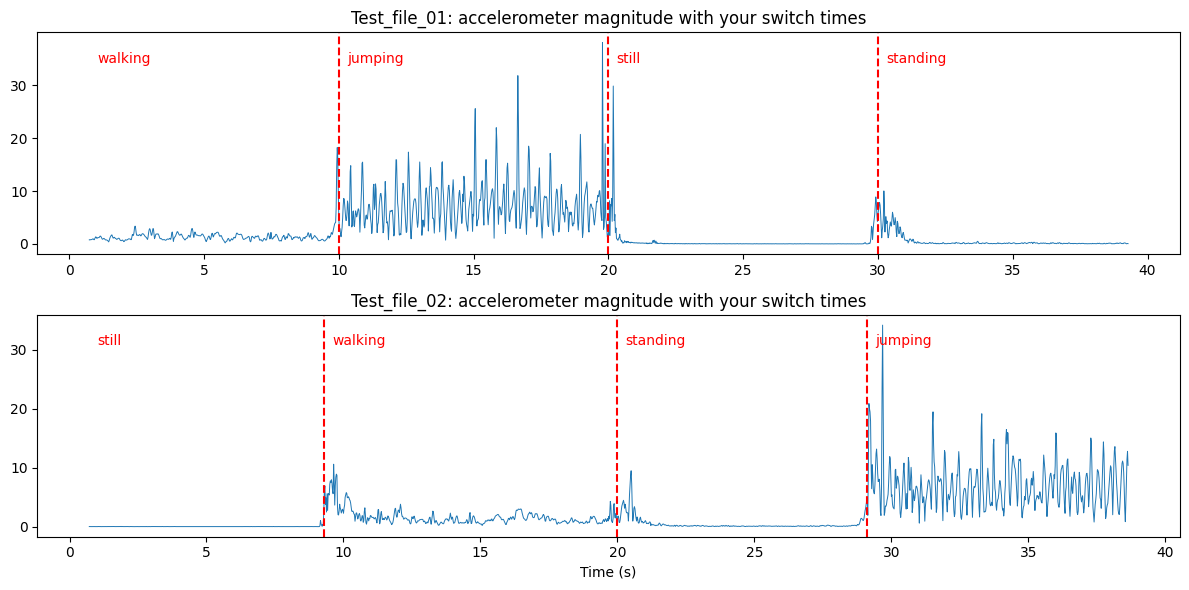

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for i, key in enumerate(test_names):
    t, arr = test_signal[key]
    mag = np.linalg.norm(arr[:, :3], axis=1)
    axes[i].plot(t, mag, lw=0.7)
    segs = truth[key]
    for sw in [s[1] for s in segs[1:]]:
        axes[i].axvline(sw, color='red', ls='--')
    for a, lo, hi in segs:
        axes[i].text(max(lo, t[0]) + 0.3, mag.max() * 0.9, a, color='red')
    axes[i].set_title(f'{key}: accelerometer magnitude with your switch times')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/hmm_project/test_signals.png', dpi=150)
plt.show()

## Step 17: Decode the unseen data with Viterbi
Runs Viterbi on both test files and prints the accuracy for each file, the overall accuracy over all windows, and the accuracy excluding the windows that straddle a switch.

In [ ]:
pred = [hmm.viterbi(X) for X in test_seqs]

y_true = np.concatenate(test_true)
y_pred = np.concatenate(pred)
bnd = np.concatenate(test_boundary)

for name, yt, yp in zip(test_names, test_true, pred):
    print(f'{name}: accuracy = {(yt == yp).mean():.3f}')

print(f'\nOverall accuracy (all {len(y_true)} windows): {(y_true == y_pred).mean():.3f}')
print(f'Accuracy excluding switch windows ({(~bnd).sum()} windows): '
      f'{(y_true[~bnd] == y_pred[~bnd]).mean():.3f}')

Test_file_01: accuracy = 0.757
Test_file_02: accuracy = 0.861

Overall accuracy (all 73 windows): 0.808
Accuracy excluding switch windows (61 windows): 0.902


## Step 18: Confusion matrix and the sensitivity, specificity and accuracy table
Builds the confusion matrix (rows are the true activity, columns the predicted one) and, for each activity treated as "one versus the rest":
- **Sensitivity** = TP / (TP + FN): the share of true windows of that activity that were found,
- **Specificity** = TN / (TN + FP): the share of windows of other activities that were correctly rejected,
- **Overall accuracy** = (TP + TN) / all windows.

The table is saved as `test_results_table.csv`.

In [ ]:
cm = np.zeros((4, 4), dtype=int)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

print('Confusion matrix (rows = true, cols = predicted):')
print(pd.DataFrame(cm, index=STATES, columns=STATES))

rows = []
for k, s in enumerate(STATES):
    TP = cm[k, k]
    FN = cm[k].sum() - TP
    FP = cm[:, k].sum() - TP
    TN = cm.sum() - TP - FN - FP
    rows.append({
        'State (Activity)': s,
        'Number of Samples': int(cm[k].sum()),
        'Sensitivity': round(TP / (TP + FN), 3),
        'Specificity': round(TN / (TN + FP), 3),
        'Overall Accuracy': round((TP + TN) / cm.sum(), 3),
    })
table = pd.DataFrame(rows)
print('\n', table.to_string(index=False))
table.to_csv('/content/drive/MyDrive/hmm_project/test_results_table.csv', index=False)

Confusion matrix (rows = true, cols = predicted):
          standing  walking  jumping  still
standing        12        3        2      0
walking          0       18        2      0
jumping          0        0       18      0
still            4        1        2     11

 State (Activity)  Number of Samples  Sensitivity  Specificity  Overall Accuracy
        standing                 17        0.706        0.929             0.877
         walking                 20        0.900        0.925             0.918
         jumping                 18        1.000        0.891             0.918
           still                 18        0.611        1.000             0.904


## Step 19: Confusion matrix plot
Plots the confusion matrix on the unseen test data and saves it as `confusion_matrix.png`.

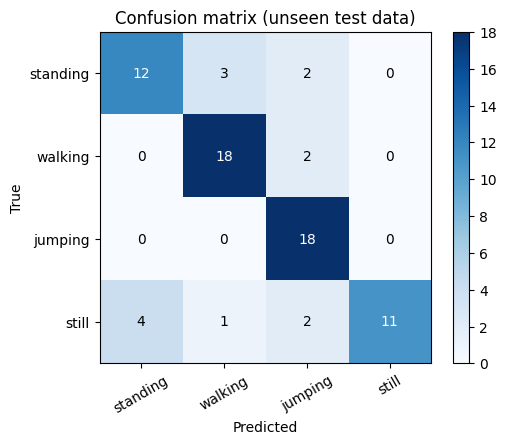

In [ ]:
plt.figure(figsize=(5.5, 4.5))
plt.imshow(cm, cmap='Blues')
plt.xticks(range(4), STATES, rotation=30)
plt.yticks(range(4), STATES)
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion matrix (unseen test data)')
plt.colorbar()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/hmm_project/confusion_matrix.png', dpi=150)
plt.show()

## Step 20: Decoded activity sequences
Plots the true activity (grey line) and the Viterbi prediction (red dashed line) over time for each test file, saved as `decoded_sequences.png`. Errors that sit next to the switches are visible here.

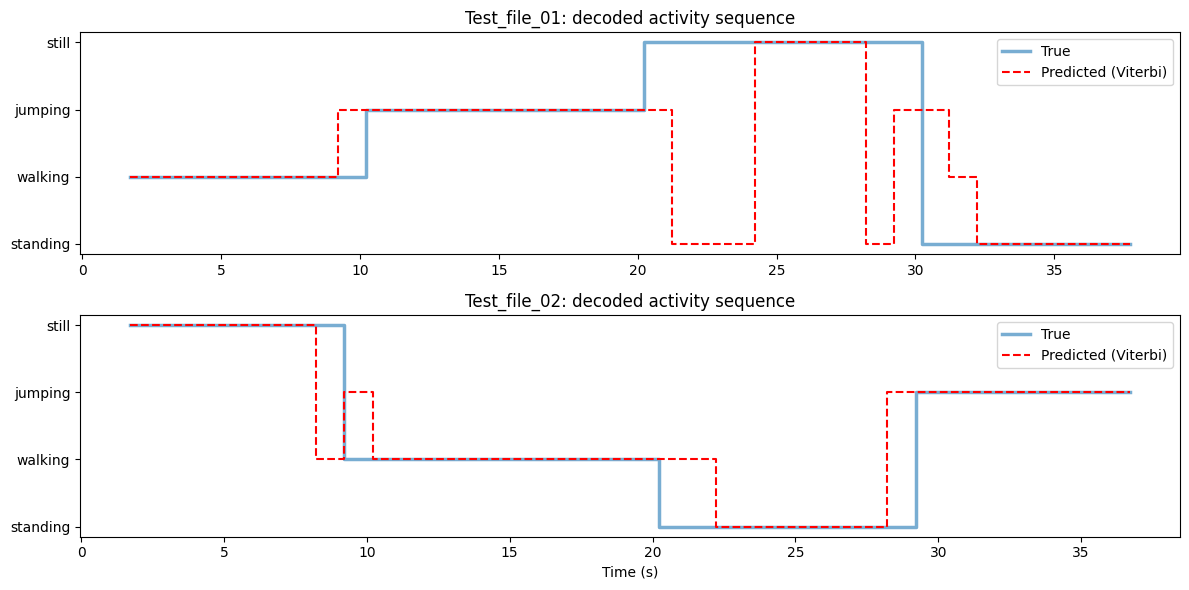

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
for i, key in enumerate(test_names):
    t, _ = test_signal[key]
    centers = [(t[s] + t[s + WIN - 1]) / 2 for s in range(0, len(t) - WIN + 1, STEP)]
    axes[i].step(centers, test_true[i], where='mid', label='True', lw=2.5, alpha=0.6)
    axes[i].step(centers, pred[i], where='mid', label='Predicted (Viterbi)', ls='--', color='red')
    axes[i].set_yticks(range(4)); axes[i].set_yticklabels(STATES)
    axes[i].set_title(f'{key}: decoded activity sequence')
    axes[i].legend(loc='upper right')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/hmm_project/decoded_sequences.png', dpi=150)
plt.show()

---
# Analysis and Reflection

## Results summary
- **Training:** Baum-Welch converged in 3 iterations (log-likelihood 533.07 to 534.23). Training accuracy was 1.000 both before and after training, which is expected because the model was initialized from the labels. It is not evidence of generalization.
- **Unseen data (2 files, 73 windows):** overall accuracy **0.808** (0.757 on Test_file_01, 0.861 on Test_file_02), and **0.902** when the 12 windows that straddle an activity switch are excluded. Of the 14 errors, 8 were in switch windows.

| Activity | Samples | Sensitivity | Specificity | Overall accuracy |
|---|---|---|---|---|
| Standing | 17 | 0.706 | 0.929 | 0.877 |
| Walking | 20 | 0.900 | 0.925 | 0.918 |
| Jumping | 18 | 1.000 | 0.891 | 0.918 |
| Still | 18 | 0.611 | 1.000 | 0.904 |

**How the unseen data was obtained:** two new Sensor Logger recordings, each containing all four activities back to back (about 10 s each) in a different order (walking, jumping, still, standing; and still, walking, standing, jumping). They were recorded in a different place and a separate session from the training clips (file timestamps 18:32 and 18:35 versus 10:08 to 10:53 for training), with the phone held in one hand lower than in training, and with no pauses between activities. They were not used for training or for choosing features. The ground truth comes from my timing notes, with two switch times in Test_file_02 refined from the signal.

**Does the model generalize?** Reasonably well. Jumping and walking transferred almost perfectly, and most errors happen within a few seconds of a switch. The conditions differed from training (place, phone position, no pauses), so this is a fair test, but with only 73 windows each sensitivity rests on 17 to 20 windows, and one more mistake changes it noticeably.

## 1. Which activities were easiest or hardest to distinguish?
**Easiest: jumping and walking.** Jumping was found in every window (sensitivity 1.000) and walking in 18 of 20 (0.900). Jumping has the highest intensity (`acc_std`, `acc_sma`, `acc_energy`) and the most periodic spectrum (lowest `acc_entropy`), as the emission heatmap shows. Walking has a clear step rhythm (dominant frequency about 1.4 Hz in the training data).

**Hardest: standing and still.** Still (0.611) and standing (0.706) had the lowest sensitivity. Both are low-motion states with similar accelerometer signals, so the gyroscope variance is the main separator (the mean `gyro_std` differs by about two orders of magnitude between them in the training data). On the unseen data, 4 of the 7 missed still windows were labelled standing (2 jumping, 1 walking), and 3 of the 5 missed standing windows were labelled walking (2 jumping). The model never predicted still for another activity (specificity 1.000), but jumping received 6 windows from other activities (specificity 0.891).

Part of the difficulty comes from how I recorded: with no pause between activities, the settling movement after a switch (for example after jumping, or when getting into the standing position) was decoded as motion for a few seconds.

## 2. How do the transition probabilities reflect realistic behavior?
Every activity has a strong self-transition: standing 0.77, walking 0.82, jumping 0.82, still 0.86. This is realistic, because a person does not change activity every second, so the activity in one window very likely continues into the next. Since windows step by 1 s, the expected stay in a state is 1 / (1 - a_ii), about 4.4 s for standing, 5.5 s for walking and jumping, and 6.9 s for still.

In Viterbi decoding this acts as a smoother: a single noisy window rarely flips the decoded activity, which is why the middle of each segment was decoded correctly. The cost is a slower reaction at switches (for example in Test_file_02 the model kept predicting walking for about 2 s after I started standing).

**Limitation:** the off-diagonal values (0.03 to 0.12) are not real habits. The training sessions were built by chaining single-activity clips in random order, so these values (and the initial probabilities, for example standing 0.47 and jumping 0.06) come from my random ordering and only 17 sessions. The high self-transition values also mostly reflect the short clip length (5 to 6 windows per clip).

## 3. How did sensor noise and the sampling rate affect the model?
**Sampling rate.** I set 100 Hz, but the timestamps showed about 52.7 Hz, consistently across activities with no dropouts. I harmonized everything to 50 Hz, which gives a Nyquist limit of 25 Hz and a frequency resolution of 0.5 Hz with 2 s windows. Walking (about 1.4 Hz) and jumping are far below the limit, so 50 Hz was enough.

**Noise.** Noise mattered most in the low-motion states. When the phone is still, the gyroscope reads about 0.001 and the accelerometer shows only noise, so the FFT peak lands on a random noise frequency (the mean `acc_domfreq` for still was about 8.1 Hz, compared with 1.4 Hz for walking). This works as a "no rhythm" signature, but it depends on noise, not on behavior. Standing has a small body sway that overlaps with this noise floor, which is one reason standing and still were the weakest classes. The settling spikes at activity switches (for example near 20 s and 30 s in Test_file_01) are another source of error.

I only tested one sampling rate (50 Hz) and one window size (2 s), so I cannot say how sensitive the results are to these choices.

## 4. What improvements could be made?
1. **More and more varied data:** several sessions, phone positions (hand, pocket, bag) and participants, and test on a held-out session or person. Only one participant, one phone and 73 test windows limit how far the results can be trusted.
2. **Long, natural recordings with annotated labels,** so that the transition matrix and initial probabilities describe real behavior instead of my random chaining.
3. **Better features for standing versus still:** low-frequency band power for body sway, gyroscope spectral energy and entropy (only `gyro_std` and `gyro_domfreq` were used), jerk, and peak counts.
4. **Shorter windows or a smaller step** to locate switches more precisely (the model reacted about 1 to 2 s early or late), while testing the loss of frequency resolution.
5. **A richer emission model:** full covariance or a mixture of Gaussians per state, and random initializations of Baum-Welch to see whether the model finds the activities without label initialization.
6. **Additional sensors** such as the magnetometer or barometer, and orientation-independent features, since the phone position differed between training and test.



